# Feature Spaces and Embeddings

1. Feature vectors and distances
2. PCA by hand (2D toy data)
3. PCA on real data: handwritten digits
4. Embeddings: words as vectors

You only need `numpy`, `matplotlib` and `scikit-learn`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.datasets import load_digits
from sklearn.preprocessing import StandardScaler

np.random.seed(42)
plt.rcParams["figure.figsize"] = (6, 4)

## 1. Feature vectors and distances
Each row in a dataset is a **feature vector**. Here, each fruit is described by three features:
`[weight (g), sweetness, colour]`.

In [2]:
features = ["weight", "sweetness", "colour"]
apple1 = np.array([150, 11.2, 0.9])
apple2 = np.array([165, 10.8, 0.8])
orange = np.array([210,  8.1, 0.4])

print("apple1 is a vector with", apple1.shape[0], "dimensions:", apple1)

apple1 is a vector with 3 dimensions: [150.   11.2   0.9]


**Euclidean distance** = straight-line distance between two points.
**Cosine similarity** = how similar the *directions* are (1 = same direction, 0 = unrelated).

In [3]:
def euclidean(a, b):
    return np.sqrt(np.sum((a - b) ** 2))      # same as np.linalg.norm(a - b)

def cosine_similarity(a, b):
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))

print("distance apple1-apple2:", round(euclidean(apple1, apple2), 2))
print("distance apple1-orange:", round(euclidean(apple1, orange), 2))

distance apple1-apple2: 15.01
distance apple1-orange: 60.08


⚠️ Notice that **weight** dominates the distance because it is measured in grams (big numbers).
That is why we **scale** features first (last week's topic):

In [4]:
data = np.array([apple1, apple2, orange])
scaled = StandardScaler().fit_transform(data)   # mean 0, std 1 per column
a1, a2, o = scaled

print("scaled distance apple1-apple2:", round(euclidean(a1, a2), 2))
print("scaled distance apple1-orange:", round(euclidean(a1, o), 2))

scaled distance apple1-apple2: 0.8
scaled distance apple1-orange: 4.0


### The feature space
With two features we can **plot** every fruit as a point. Similar fruits form clouds.

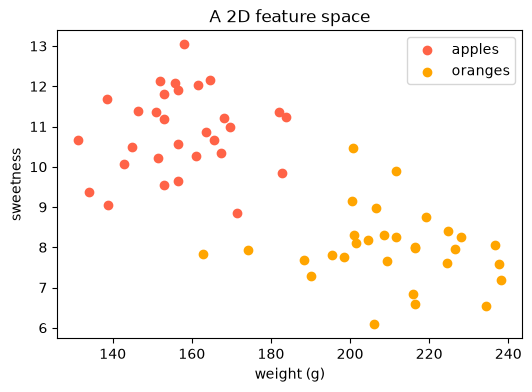

In [5]:
apples  = np.column_stack([np.random.normal(160, 15, 30), np.random.normal(11, 1.1, 30)])
oranges = np.column_stack([np.random.normal(210, 18, 30), np.random.normal(8, 1.0, 30)])

plt.scatter(apples[:, 0], apples[:, 1], label="apples", c="tomato")
plt.scatter(oranges[:, 0], oranges[:, 1], label="oranges", c="orange")
plt.xlabel("weight (g)")
plt.ylabel("sweetness")
plt.title("A 2D feature space")
plt.legend()
plt.show()

**Try it:** Add a new fruit, e.g. `mystery = np.array([175, 10.0])`. Plot it as a black `x`.
Which group is it closest to? Compute its distance to the *mean* apple and the *mean* orange.

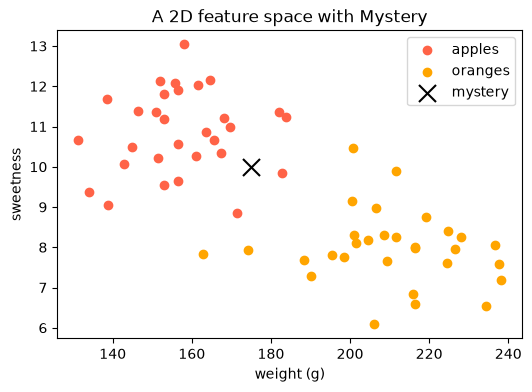

mean apple:  [157.2  10.9]
mean orange: [210.2   8. ]
distance to mean apple:  17.84
distance to mean orange: 35.29
scaled distance to mean apple:  0.77
scaled distance to mean orange: 1.64


In [6]:
# --- Solution ---
mystery = np.array([175, 10.0])

plt.scatter(apples[:, 0], apples[:, 1], label="apples", c="tomato")
plt.scatter(oranges[:, 0], oranges[:, 1], label="oranges", c="orange")
plt.scatter(mystery[0], mystery[1], c="black", marker="x", s=150, label="mystery")
plt.xlabel("weight (g)")
plt.ylabel("sweetness")
plt.title("A 2D feature space with Mystery")
plt.legend()
plt.show()

mean_apple = apples.mean(axis=0)
mean_orange = oranges.mean(axis=0)
print("mean apple: ", mean_apple.round(1))
print("mean orange:", mean_orange.round(1))
print("distance to mean apple: ", round(euclidean(mystery, mean_apple), 2))
print("distance to mean orange:", round(euclidean(mystery, mean_orange), 2))

# Bonus: the same comparison after scaling (fit the scaler on the known fruit only)
scaler = StandardScaler().fit(np.vstack([apples, oranges]))
m_s = scaler.transform([mystery])[0]
a_s = scaler.transform([mean_apple])[0]
o_s = scaler.transform([mean_orange])[0]
print("scaled distance to mean apple: ", round(euclidean(m_s, a_s), 2))
print("scaled distance to mean orange:", round(euclidean(m_s, o_s), 2))

# What we see:
# - The black x sits between the clouds, but nearer the apples.
# - It is closer to the mean apple (about 18) than to the mean orange (about 35), so we would call it an apple.
# - Careful: the raw distance is almost only about weight (175 g vs 157 g and 210 g).
#   The sweetness difference (10 vs 10.9 and 8.0) hardly counts, because grams are much bigger numbers.
# - After scaling both features count equally. The answer is still "apple" (0.77 vs 1.64),
#   but now sweetness helps decide too. Here both features agree; in other data they might not.

## 2. PCA by hand
PCA finds the directions where the data **varies the most**. We do it in four steps on 2D data,
so we can see what happens.

In [7]:
# correlated 2D data (a stretched, tilted cloud)
X = np.random.multivariate_normal(mean=[2, 3], cov=[[3, 2.2], [2.2, 2]], size=200)

# Step 1: center the data
X_centered = X - X.mean(axis=0)

# Step 2+3: the principal components are the eigenvectors of the covariance matrix
cov = np.cov(X_centered.T)
eigenvalues, eigenvectors = np.linalg.eigh(cov)

# sort from largest to smallest variance
order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]

print("variance along PC1, PC2:", eigenvalues.round(2))
print("explained variance ratio:", (eigenvalues / eigenvalues.sum()).round(3))

variance along PC1, PC2: [4.93 0.23]
explained variance ratio: [0.956 0.044]


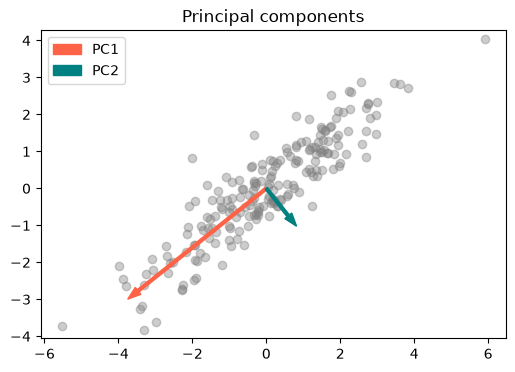

In [8]:
plt.scatter(X_centered[:, 0], X_centered[:, 1], alpha=0.4, c="gray")
for i, color in enumerate(["tomato", "teal"]):
    direction = eigenvectors[:, i] * np.sqrt(eigenvalues[i]) * 2
    plt.arrow(0, 0, *direction, width=0.08, color=color, label=f"PC{i+1}")
plt.axis("equal")
plt.legend()
plt.title("Principal components")
plt.show()

**Step 4: project.** Each point gets new coordinates along the components.
If we keep only PC1, our 2D data becomes 1D.

same result as sklearn: True


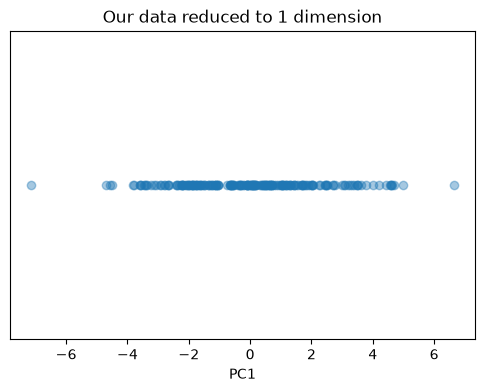

In [9]:
Z = X_centered @ eigenvectors          # coordinates in the PC system (still 2D)
z1 = Z[:, 0]                           # keep only PC1 -> 1D

# Compare with scikit-learn (the sign of a component can be flipped, that's fine)
Z_sklearn = PCA(n_components=2).fit_transform(X)
print("same result as sklearn:", np.allclose(np.abs(Z), np.abs(Z_sklearn)))

plt.scatter(z1, np.zeros_like(z1), alpha=0.4)
plt.yticks([])
plt.xlabel("PC1")
plt.title("Our data reduced to 1 dimension")
plt.show()

**Try it:** Change the covariance to `[[3, 0], [0, 3]]` (a round cloud) and run part 2 again.
What happens to the explained variance ratio? Why does PCA not help much here?

variance along PC1, PC2: [2.98 2.59]
explained variance ratio: [0.535 0.465]


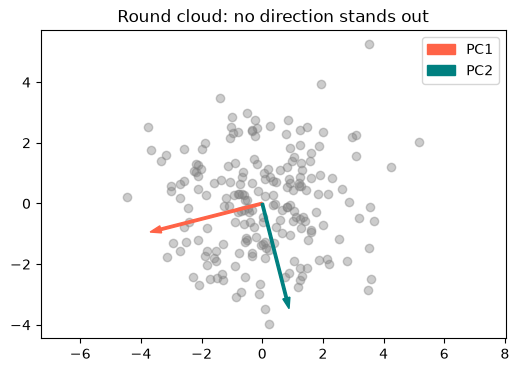

In [14]:
# --- Solution: a round cloud (no correlation, same spread in all directions) ---
X_round = np.random.multivariate_normal(mean=[2, 3], cov=[[3, 0], [0, 3]], size=200)
X_round_c = X_round - X_round.mean(axis=0)

vals, vecs = np.linalg.eigh(np.cov(X_round_c.T))
order = np.argsort(vals)[::-1]
vals, vecs = vals[order], vecs[:, order]

print("variance along PC1, PC2:", vals.round(2))
print("explained variance ratio:", (vals / vals.sum()).round(3))

plt.scatter(X_round_c[:, 0], X_round_c[:, 1], alpha=0.4, c="gray")
for i, color in enumerate(["tomato", "teal"]):
    direction = vecs[:, i] * np.sqrt(vals[i]) * 2
    plt.arrow(0, 0, *direction, width=0.08, color=color, label=f"PC{i+1}")
plt.axis("equal")
plt.legend()
plt.title("Round cloud: no direction stands out")
plt.show()

# What we see:
# - The explained variance ratio is about 0.54 / 0.46 instead of 0.96 / 0.04 for the stretched cloud.
# - In a round cloud the data spreads (almost) equally in every direction. There is no "long axis".
# - PC1 just points wherever this random sample happens to spread a little more.
#   Run it again and the arrows point somewhere else.
# - Why PCA does not help: dropping PC2 would throw away almost half the information.
#   PCA only helps when the features are correlated, so that a few directions carry most of the variance.

## 3. PCA on real data: handwritten digits
1797 images of digits, each 8×8 pixels = **64 features**.

data shape: (1797, 64)


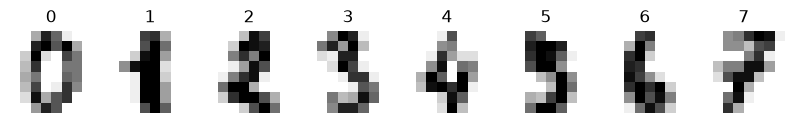

the first image as a feature vector:
 [ 0.  0.  5. 13.  9.  1.  0.  0.  0.  0. 13. 15. 10. 15.  5.  0.  0.  3.
 15.  2.  0. 11.  8.  0.  0.  4. 12.  0.  0.  8.  8.  0.  0.  5.  8.  0.
  0.  9.  8.  0.  0.  4. 11.  0.  1. 12.  7.  0.  0.  2. 14.  5. 10. 12.
  0.  0.  0.  0.  6. 13. 10.  0.  0.  0.]


In [15]:
digits = load_digits()
X, y = digits.data, digits.target
print("data shape:", X.shape)        # (samples, features)

fig, axes = plt.subplots(1, 8, figsize=(10, 2))
for ax, img, label in zip(axes, digits.images, y):
    ax.imshow(img, cmap="gray_r")
    ax.set_title(label)
    ax.axis("off")
plt.show()

print("the first image as a feature vector:\n", X[0])

### From 64D to 2D

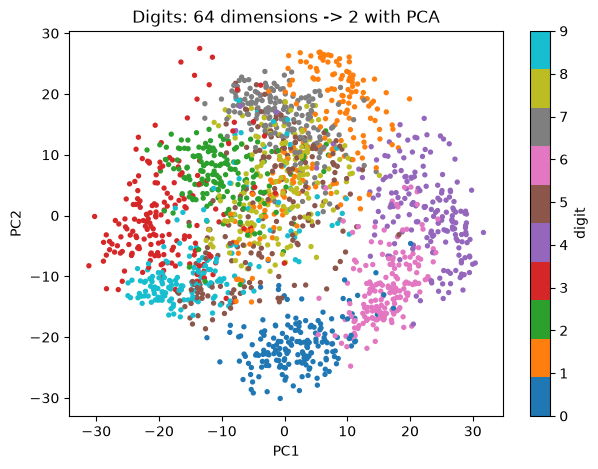

variance kept by 2 components: 0.285


In [16]:
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X)          # note: labels y are NOT used!

plt.figure(figsize=(7, 5))
scatter = plt.scatter(X_2d[:, 0], X_2d[:, 1], c=y, cmap="tab10", s=8)
plt.colorbar(scatter, label="digit")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Digits: 64 dimensions -> 2 with PCA")
plt.show()

print("variance kept by 2 components:", pca.explained_variance_ratio_.sum().round(3))

### How many components should we keep?

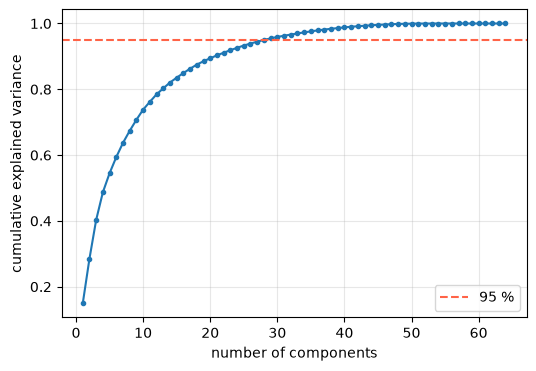

29 components keep 95 % of the variance


In [17]:
pca_full = PCA().fit(X)
cumulative = np.cumsum(pca_full.explained_variance_ratio_)

plt.plot(range(1, 65), cumulative, marker=".")
plt.axhline(0.95, color="tomato", linestyle="--", label="95 %")
plt.xlabel("number of components")
plt.ylabel("cumulative explained variance")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

k95 = np.argmax(cumulative >= 0.95) + 1
print(f"{k95} components keep 95 % of the variance")

### What is lost? Reconstruct images from k components
`inverse_transform` maps the compressed vectors back to 64 pixels.

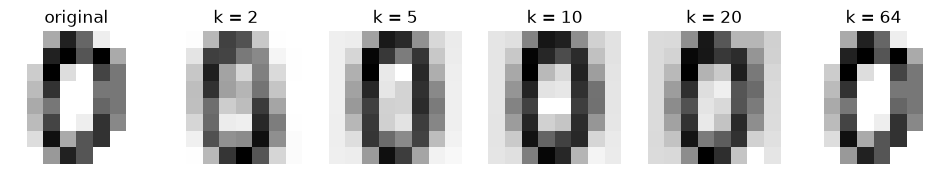

In [18]:
ks = [2, 5, 10, 20, 64]
fig, axes = plt.subplots(1, len(ks) + 1, figsize=(12, 2.2))
axes[0].imshow(X[0].reshape(8, 8), cmap="gray_r")
axes[0].set_title("original")
for ax, k in zip(axes[1:], ks):
    p = PCA(n_components=k).fit(X)
    restored = p.inverse_transform(p.transform(X[:1]))
    ax.imshow(restored.reshape(8, 8), cmap="gray_r")
    ax.set_title(f"k = {k}")
for ax in axes:
    ax.axis("off")
plt.show()

### Bonus: t-SNE (non-linear, only for visualisation)
This may take a few seconds.

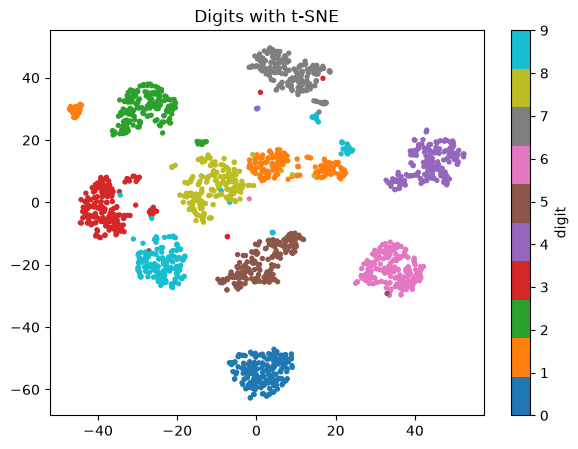

In [19]:
from sklearn.manifold import TSNE

X_tsne = TSNE(n_components=2, random_state=0).fit_transform(X)
plt.figure(figsize=(7, 5))
plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=y, cmap="tab10", s=8)
plt.colorbar(label="digit")
plt.title("Digits with t-SNE")
plt.show()

**Try it:**
1. Which digits overlap the most in the PCA plot? Does t-SNE separate them better?
2. Train a classifier (e.g. `KNeighborsClassifier`) on the original 64 features and on 10 PCA components.
   Compare accuracy and training time.

In [22]:
# --- Solution ---
import time
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split, cross_val_predict

# 1. Which digits overlap most in the PCA plot?
#    Idea: let a nearest-neighbour classifier look ONLY at the 2D plot coordinates.
#    Digits it mixes up are digits that lie on top of each other in the plot.
pred_pca = cross_val_predict(KNeighborsClassifier(), X_2d, y, cv=5)
pred_tsne = cross_val_predict(KNeighborsClassifier(), X_tsne, y, cv=5)
print(f"neighbours in the 2D PCA plot share the label:   {(pred_pca == y).mean():.1%}")
print(f"neighbours in the 2D t-SNE plot share the label: {(pred_tsne == y).mean():.1%}")

mixups = {}
for true_digit, guess in zip(y, pred_pca):
    if true_digit != guess:
        pair = tuple(sorted((true_digit, guess)))
        mixups[pair] = mixups.get(pair, 0) + 1
print("most mixed-up digit pairs in the PCA plot:")
for pair, count in sorted(mixups.items(), key=lambda item: item[1], reverse=True)[:5]:
    print(f"  {pair[0]} and {pair[1]}: {count} times")

# What we see (1):
# - In the 2D PCA plot only about 60 % of the points have a neighbour with the same digit.
#   In the 2D t-SNE plot it is about 98 %: t-SNE separates the digits much better.
# - The most mixed-up pairs in the PCA plot are 1 & 8, 5 & 8, 3 & 9 and 5 & 9.
#   They lie on top of each other in the PCA plot, even though a classifier can tell them apart in 64D (see below).
# - Note: t-SNE was run on all the data, so this measures how readable the plot is,
#   not how good a real classifier would be.

# 2. k-NN on all 64 pixels vs 10 PCA components
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)

pca10 = PCA(n_components=10).fit(X_train)          # fit PCA on training data only
X_train_10 = pca10.transform(X_train)
X_test_10 = pca10.transform(X_test)

for name, Xtr, Xte in [("64 pixels", X_train, X_test), ("10 components", X_train_10, X_test_10)]:
    model = KNeighborsClassifier().fit(Xtr, y_train)
    times = []
    for _ in range(5):                                # repeat: single timings are noisy
        start = time.perf_counter()
        acc = model.score(Xte, y_test)                # k-NN does its real work when predicting
        times.append((time.perf_counter() - start) * 1000)
    print(f"{name:14s} accuracy {acc:.1%}   fastest of 5 runs: {min(times):.1f} ms")

# What we see (2):
# - 64 pixels: about 98 % correct. 10 components: about 97 %. We keep almost all accuracy with 1/6 of the features.
# - The times are only a few milliseconds, and the 10-component version is not clearly faster.
#   This dataset is tiny, and scikit-learn chooses different search methods for 10 and 64 features.
#   The speed gain from fewer features shows up with large datasets (many points, many features).

neighbours in the 2D PCA plot share the label:   60.3%
neighbours in the 2D t-SNE plot share the label: 97.6%
most mixed-up digit pairs in the PCA plot:
  1 and 8: 69 times
  5 and 8: 58 times
  3 and 9: 57 times
  5 and 9: 54 times
  5 and 7: 43 times
64 pixels      accuracy 98.0%   fastest of 5 runs: 5.0 ms
10 components  accuracy 96.9%   fastest of 5 runs: 2.8 ms


## 4. Embeddings: words as vectors
An **embedding** is a short, dense vector learned so that similar things are close.
Real embeddings have hundreds of dimensions and are learned from huge amounts of text.
Here we use **hand-made 4D vectors** so we can see the idea.

Dimensions (only for intuition — real embeddings have no readable meaning per dimension):
`[royalty, male, female, animal]`

In [23]:
words = {
    "king":   np.array([0.95, 0.90, 0.05, 0.02]),
    "queen":  np.array([0.95, 0.05, 0.90, 0.02]),
    "man":    np.array([0.10, 0.92, 0.08, 0.05]),
    "woman":  np.array([0.10, 0.06, 0.94, 0.05]),
    "prince": np.array([0.80, 0.85, 0.05, 0.03]),
    "cat":    np.array([0.05, 0.40, 0.45, 0.95]),
    "dog":    np.array([0.05, 0.50, 0.40, 0.97]),
}

print("cat vs dog:  ", round(cosine_similarity(words["cat"], words["dog"]), 3))
print("cat vs king: ", round(cosine_similarity(words["cat"], words["king"]), 3))

cat vs dog:   0.996
cat vs king:  0.305


### Nearest neighbours

In [24]:
def most_similar(vector, exclude=()):
    scores = {w: cosine_similarity(vector, v) for w, v in words.items() if w not in exclude}
    return sorted(scores.items(), key=lambda item: item[1], reverse=True)

for word, score in most_similar(words["king"], exclude=["king"]):
    print(f"{word:7s} {score:.3f}")

prince  0.998
man     0.762
queen   0.579
dog     0.352
cat     0.305
woman   0.159


### Vector arithmetic: king − man + woman ≈ ?

In [25]:
result = words["king"] - words["man"] + words["woman"]
best_word, best_score = most_similar(result, exclude=["king", "man", "woman"])[0]
print(f"closest word: {best_word} (cosine similarity {best_score:.3f})")

closest word: queen (cosine similarity 1.000)


### Visualise the embeddings with PCA (4D -> 2D)

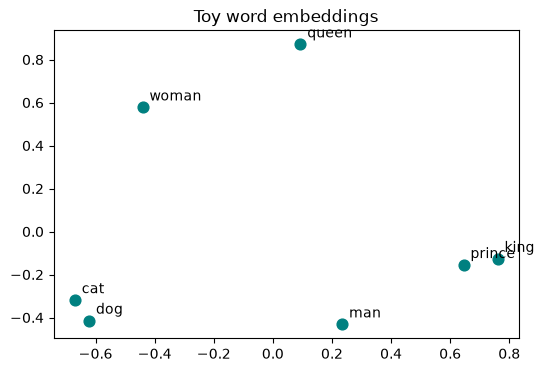

In [26]:
names = list(words)
vectors = np.array([words[w] for w in names])
points = PCA(n_components=2).fit_transform(vectors)

plt.scatter(points[:, 0], points[:, 1], s=60, c="teal")
for name, (px, py) in zip(names, points):
    plt.annotate(name, (px, py), textcoords="offset points", xytext=(5, 5))
plt.title("Toy word embeddings")
plt.show()

**Try it:** Add `"princess"`, `"kitten"` and `"puppy"` with your own vectors.
Do they land where you expect? What is the closest word to `"prince" - "man" + "woman"`?

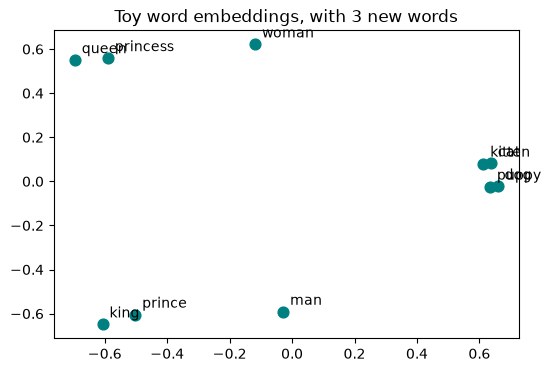

prince - man + woman, top 3:
  princess 0.999
  queen    0.995
  king     0.502

nearest to kitten: [('cat', np.float64(0.9995549625612744)), ('dog', np.float64(0.9954845809587055))]


In [27]:
# --- Solution ---
# dimensions: [royalty, male, female, animal]
words["princess"] = np.array([0.80, 0.05, 0.90, 0.03])
words["kitten"]   = np.array([0.03, 0.40, 0.45, 0.90])
words["puppy"]    = np.array([0.03, 0.50, 0.40, 0.92])

names = list(words)
vectors = np.array([words[w] for w in names])
points = PCA(n_components=2).fit_transform(vectors)

plt.scatter(points[:, 0], points[:, 1], s=60, c="teal")
for name, (px, py) in zip(names, points):
    plt.annotate(name, (px, py), textcoords="offset points", xytext=(5, 5))
plt.title("Toy word embeddings, with 3 new words")
plt.show()

result = words["prince"] - words["man"] + words["woman"]
print("prince - man + woman, top 3:")
for word, score in most_similar(result, exclude=["prince", "man", "woman"])[:3]:
    print(f"  {word:8s} {score:.3f}")

print("\nnearest to kitten:", most_similar(words["kitten"], exclude=["kitten"])[:2])

# What we see:
# - princess lands next to queen, kitten next to cat, puppy next to dog: similar vectors -> nearby points.
#   (Their labels overlap in the plot because the points almost sit on top of each other.)
# - prince - man + woman gives princess as the closest word (0.999), with queen close behind (0.995).
#   The "male -> female" step works for prince/princess just like for king/queen.
# - We made these vectors ourselves, so the result is built in. In real embeddings the
#   vectors are learned from text, and analogies like this only work approximately.

### Optional: real sentence embeddings
Requires `pip install sentence-transformers` and an internet connection the first time (downloads a small model, ~90 MB).
The cell is skipped if the library is not installed.

In [ ]:
try:
    from sentence_transformers import SentenceTransformer
    model = SentenceTransformer("all-MiniLM-L6-v2")
    sentences = [
        "The cat sits on the mat.",
        "A kitten is sleeping on the rug.",
        "The stock market fell today.",
        "Shares dropped sharply this morning."
    ]
    emb = model.encode(sentences)
    print("each sentence ->", emb.shape[1], "dimensions")
    for i in range(len(sentences)):
        for j in range(i + 1, len(sentences)):
            print(f"{cosine_similarity(emb[i], emb[j]):.2f}  {sentences[i]!r} vs {sentences[j]!r}")
except ImportError:
    print("sentence-transformers is not installed - skipping this optional part.")

## Summary
- A data point is a **vector**; features are the axes of a **feature space**.
- **Distance** (Euclidean or cosine) measures similarity — scale your features first.
- **PCA** finds the directions of largest variance and reduces dimensions, great for plots and compression.
- **Embeddings** are learned vectors where similar meaning means nearby points.